# IDEAS #

> **comment généraliser cela pour les dimensions supérieures**

> **Interfaces différentes (pas forcément des rectangles) / mods différents**

> **Creer un chemin d'un point a a un point b a l'aide de polyominos**

# CODE #

In [1]:
import numpy as np
from scipy.signal import convolve2d  # utilise dans la fonction outline2

In [2]:
def to_square(pol):
    res = np.zeros((max(pol.shape), max(pol.shape)), dtype="int64")
    res[:pol.shape[0], :pol.shape[1]] = pol
    return res

def generate(pol):
    x_min, x_max, y_min, y_max = -1, -1, -1, -1
    for x in range(pol.shape[1]):
        if pol[:,x].max() == 1 and x_min == -1:
            x_min = x
        if pol[:,-x-1].max() == 1 and x_max == -1:
            x_max = pol.shape[1] - x
        if x_max != -1 and x_min != -1: break
    for y in range(pol.shape[0]):
        if pol[y,:].max() == 1 and y_min == -1:
            y_min = y
        if pol[-y-1,:].max() == 1 and y_max == -1:
            y_max = pol.shape[0] - y
        if y_max != -1 and y_min != -1: break
    if x_min == -1 or y_min == -1: 
        return np.ones((0, 0))
    return to_square(pol[y_min:y_max, x_min:x_max])

In [3]:
def minimize(pol):
    x_min, x_max, y_min, y_max = -1, -1, -1, -1
    for x in range(pol.shape[1]):
        if pol[:,x].max() == 1 and x_min == -1:
            x_min = x
        if pol[:,-x-1].max() == 1 and x_max == -1:
            x_max = pol.shape[1] - x
        if x_max != -1 and x_min != -1: break
    for y in range(pol.shape[0]):
        if pol[y,:].max() == 1 and y_min == -1:
            y_min = y
        if pol[-y-1,:].max() == 1 and y_max == -1:
            y_max = pol.shape[0] - y
        if y_max != -1 and y_min != -1: break
    if x_min == -1 or y_min == -1: 
        return np.ones((0, 0))
    return pol[y_min:y_max, x_min:x_max]

In [4]:
def rotation(pol):
    return np.rot90(pol)

In [5]:
def symetrie_h(pol):
    return np.flip(pol, axis=0)
    
def symetrie_v(pol):
    return np.flip(pol, axis=1)

In [6]:
def equals(pol1, pol2):
    return pol1.shape == pol2.shape and (pol1 == pol2).all()

def in_classe(pol, classe):
    for j in range(len(classe)):
        if equals(pol, classe[j]):
            return True
    return False

def classe_rotation(pol):
    liste=[pol]
    for i in range(3):
        p = rotation(liste[-1])
        if not in_classe(p, liste): 
            liste.append(p)
    return liste

def classe_symetrie(pol):
    liste = [pol]
    functions = (symetrie_v, symetrie_h, symetrie_v)
    for i in range(3):
        p = functions[i](liste[-1])
        if not in_classe(p, liste):
            liste.append(p)
    return liste

In [7]:
def classe_symetrie_mieux(pol):
    liste = [pol]
    for i in range(3):
        if i % 2 == 0:
            pol = symetrie_v(pol)
        else:
            pol = symetrie_h(pol)
        if not in_classe(pol, liste):
            liste.append(pol)
    return liste

In [8]:
def est_correct(pol):
    long = len(pol)
    large = len(pol[0])
    for i in range(long):
        for j in range(large):
            if pol[i+1] == 0 and pol[j+1] == 0:
                return False
            else:
                return True  

In [9]:
def draw_square(x, y):
    return polygon2d([(x, y), (x+1, y), (x+1, y+1), (x, y+1)])

def grille(width, height):
    return polygon2d([(0, 0), (width, 0), (width, height), (0, height)], color="red", fill=False)

def draw(pol):
    res = grille(pol.shape[1], pol.shape[0])
    y_max = pol.shape[0]
    pol = list(pol)
    for y in range(len(pol)):
        for x in range(len(pol[y])):
            if pol[y][x] == 1:
                res += draw_square(x, y_max-y-1)
    return res

In [10]:
def to_tuple(pol):
    return tuple(map(tuple, pol))

In [11]:
def generate_pol_aux(area, last_pos, pol, res):
    if area == 0: 
        res.add(to_tuple(generate(pol)))
        return None
    directions = ((1, 0), (0, -1), (-1, 0), (0, 1)) # Il va commencer en bas, puis a droite, haut et gauche.
    for i in range(4):
        pos = last_pos[0]+directions[i][0], last_pos[1]+directions[i][1]
        if pol[pos] == 0:
            new_pol = pol.copy()
            new_pol[pos] = 1
            generate_pol_aux(area-1, pos, new_pol, res)

def generate_all(area):
    res = set()
    base = np.zeros((area*2-1, area*2-1))
    base[area-1, area-1] = 1
    generate_pol_aux(area-1, (area-1, area-1), base, res)
    return res

In [12]:
# Avec la représentation avec les matrices, les degrés sont facilement calculables grâce au périmètre et à 
# l'air du polyomino:
# Dp = 4*aire
# Dr = Dp-perimetre = 4*aire - perimetre

def potential_degree(pol):
    return pol.sum()*4

def perimeter(pol):
    """ Technique vue en ISD : On soustrait avec la matrice translatée pour faire ressortir les contours """
    vert1 = np.zeros((pol.shape[0]+1, pol.shape[1]), dtype="int64")
    vert2 = np.zeros((pol.shape[0]+1, pol.shape[1]), dtype="int64")
    hor1 = np.zeros((pol.shape[0], pol.shape[1]+1), dtype="int64")
    hor2 = np.zeros((pol.shape[0], pol.shape[1]+1), dtype="int64")
    vert1[1:, :] = pol
    vert2[:-1, :] = pol
    hor1[:, 1:] = pol
    hor2[:, :-1] = pol
    return np.abs(hor1-hor2).sum() + np.abs(vert1-vert2).sum()

def real_degree(pol):
    return potential_degree(pol) - perimeter(pol)

def degrees(pol):
    pr = potential_degree(pol)
    return pr, pr-perimeter(pol)

def outline(pol):
    res = np.zeros((pol.shape[0]+2, pol.shape[1]+2), dtype="int64")
    hor = np.zeros((pol.shape[0], pol.shape[1]+1), dtype="int64")
    vert = np.zeros((pol.shape[0]+1, pol.shape[1]), dtype="int64")
    hor[:, 1:] += pol
    hor[:, :-1] -= pol
    hor = np.abs(hor)
    res[1:-1, :res.shape[1]//2] += hor[:, :res.shape[1]//2]
    res[1:-1, res.shape[1]//2+1:] += hor[:, res.shape[1]//2:]
    vert[1:, :] += pol
    vert[:-1, :] -= pol
    vert = np.abs(vert)
    res[:res.shape[0]//2, 1:-1] += vert[:res.shape[0]//2, :]
    res[res.shape[0]//2+1:, 1:-1] += vert[res.shape[0]//2:, :]
    return res

In [72]:
def size_convolving(distance):
    """ Renvoie la taille que doit avoir la matrice convolving et le nombre de 0 aux bords """
    res = 1
    distance -= 2
    while distance > 0:
        res += 1
        distance -= res + 1
    return res, -distance

def make_convolving(distance):
    """ Renvoie la matrice de convolution et la valeur du milieu """
    # Cas distance = 1 : [[0, 1, 0], [1, 4, 1], [0, 1, 0]]
    size, edges = size_convolving(distance)
    convolving = np.ones((size*2+1, size*2+1), dtype=int)
    for i in range(edges):
        convolving[i, 0] = convolving[0, i] = 0
        convolving[-i-1, 0] = convolving[-1, i] = 0
        convolving[0, -i-1] = convolving[i, -1] = 0
        convolving[-i-1, -1] = convolving[-1, -i-1] = 0
    mid = convolving.sum() - 1
    convolving[size, size] = mid
    return convolving, mid
    
def real_degree2(pol, distance=None):
    #if distance is None:
    #    distance = pol.sum()//4+1
    convolving, maximum = make_convolving(distance)
    res = convolve2d(pol, convolving, "same") - maximum
    res[res < 0] = 0
    return res.sum()

real_degree2(np.array([[0, 1, 0], [1, 1, 1]]), 3)

12

In [42]:
convolving_matrix = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])

def outline2(pol):
    res = convolve2d(pol, convolving_matrix)
    res[res < 0] = 0
    return res

In [55]:
def perimeter2(pol):
    return (outline2(pol) >= 1).sum()

In [56]:
def attribute_test(pol):
    out = outline2(pol)
    return pol.sum(), (out == 1).sum(), (out == 2).sum(), (out == 3).sum(), (out == 4).sum(), np.sqrt(pol.shape[0]**2+pol.shape[1]**2)

In [113]:
def generate_same_degrees(area, mode=None):
    pols = generate_all(area)
    res = {}
    for pol in pols:
        pol = np.array(pol)
        d = ()
        for i in range(area*2):
            d += (real_degree2(pol, i+1),)
        if d not in res:
            res[d] = [to_tuple(pol)]
        else:
            res[d].append(to_tuple(pol))
    if not mode == "verbose":
        for k in res:
            res[k] = len(res[k])
    if mode == "verbose": pass
    elif mode == "debug":
        for k in res:
            if len(res[k]) <= 8:
                res[k] = len(res[k])
    elif mode is not None:
        print(f"Warning: le mode {mode} est inconnu")
    return res

In [117]:
generate_same_degrees(7)

{(16, 28, 32, 40, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42): 2,
 (16, 26, 32, 40, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42): 8,
 (12, 20, 22, 30, 32, 32, 36, 40, 40, 40, 40, 42, 42, 42): 4,
 (12, 20, 22, 30, 34, 34, 36, 40, 42, 42, 42, 42, 42, 42): 8,
 (12, 16, 22, 30, 36, 36, 36, 40, 40, 40, 40, 42, 42, 42): 4,
 (14, 24, 28, 36, 38, 40, 42, 42, 42, 42, 42, 42, 42, 42): 8,
 (14, 22, 28, 36, 36, 38, 42, 42, 42, 42, 42, 42, 42, 42): 8,
 (12, 16, 22, 28, 30, 32, 36, 40, 42, 42, 42, 42, 42, 42): 8,
 (12, 14, 22, 24, 24, 30, 32, 32, 32, 36, 38, 38, 38, 38): 8,
 (14, 22, 28, 36, 38, 40, 42, 42, 42, 42, 42, 42, 42, 42): 8,
 (12, 16, 26, 38, 42, 42, 42, 42, 42, 42, 42, 42, 42, 42): 4,
 (14, 22, 28, 34, 34, 38, 40, 40, 40, 42, 42, 42, 42, 42): 8,
 (14, 24, 28, 38, 40, 40, 42, 42, 42, 42, 42, 42, 42, 42): 8,
 (12, 14, 22, 26, 28, 32, 34, 36, 36, 38, 40, 42, 42, 42): 8,
 (12, 18, 22, 28, 28, 32, 38, 38, 38, 40, 42, 42, 42, 42): 8,
 (12, 18, 22, 30, 32, 32, 36, 38, 38, 38, 40, 42, 42, 42): 8,
 (14, 22

In [58]:
def generate_same_attributes(area, attributes):
    pols = generate_all(area)
    res = {}
    for pol in pols:
        pol = np.array(pol)
        d = ()
        for attribute in attributes:
            d += (attribute(pol),)
        if d not in res:
            res[d] = [to_tuple(pol)]
        else:
            res[d].append(to_tuple(pol))
    return res

In [79]:
def decoupe_hor(pol):
    w = pol.shape[0]
    return (minimize(pol[:w//2, :]), minimize(pol[w//2:, :]))

def decoupe_vert(pol):
    h = pol.shape[1]
    return (minimize(pol[:, :h//2]), minimize(pol[:, h//2:]))

In [126]:
def decoupage(pol: np.ndarray):
    pol = minimize(pol)
    res = ()
    if pol.shape[0] % 2 == 0:
        decoupe = decoupe_hor(pol)
        if equals(*decoupe): 
            res += (('H', decoupe[0]),)
    if pol.shape[1] % 2 == 0:
        decoupe = decoupe_vert(pol)
        if equals(*decoupe): 
            res += (('V', decoupe[0]),)
    return res

def decoupable(pol):
    return decoupage(pol) != ()

In [115]:
def simplify_line(pol : np.ndarray):
    return pol[np.argmax(pol) : - np.argmax(pol[::-1])]

# TESTS # 

In [150]:
def add_pol(back, new_pol, decalage):
    if decalage >= back.shape[1]:
        decalage = back.shape[1]
        new_back = np.zeros((back.shape[0], back.shape[1]+new_pol.shape[1]))
        new_back[:back.shape[0], :back.shape[1]] = back
        new_back[-new_pol.shape[0]:, decalage:] = new_pol
        return new_back
    if decalage <= -back.shape[1]:
        decalage = -back.shape[1]
        new_back = np.zeros((back.shape[0], back.shape[1]+new_pol.shape[1]))
        new_back[:back.shape[0], -decalage:] = back
        new_back[-new_pol.shape[0]:, :decalage] = new_pol
        return new_back

In [153]:
add_pol(np.array([[1], [1], [1]]), np.array([[1, 1], [0, 1]]), -3)

array([[0., 1., 1.],
       [1., 1., 1.],
       [0., 1., 1.]])

In [137]:
np.array([[0, 1]]).shape

(1, 2)

In [125]:
a = np.array([[1, 1, 0],
              [0, 1, 1]])
#print(classe_symetrie_mieux(a))
print(decoupage(a))

(('H', array([[1, 1]])),)


In [118]:
simplify_line(np.array([0,0,0]))

array([], dtype=int64)

In [119]:
a = np.array([[1, 2], 
              [3, 4]])
a[:,1]

array([2, 4])

In [120]:
outline2(np.array([[1, 0, 1], [1, 1, 1]]))  # Problem here

array([[0, 1, 0, 1, 0],
       [1, 0, 3, 0, 1],
       [1, 0, 0, 0, 1],
       [0, 1, 1, 1, 0]])

In [133]:
for i in range(1, 14):
    print(len(generate_all(i)))

1
2
6
15
42
112
308
825
2255
6026
16386
43700
118334


In [130]:
g = generate_same_attributes(8, (decoupable,))
for elt in g:
    print(f"{elt}: {len(g[elt])}")

(False,): 785
(True,): 40


((6, 8, 2, 0, 0, 4.242640687119285),): 16


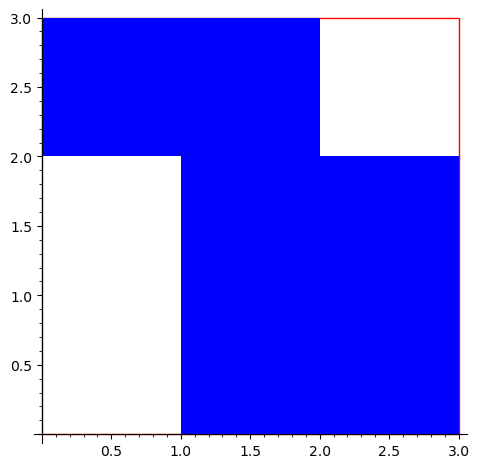

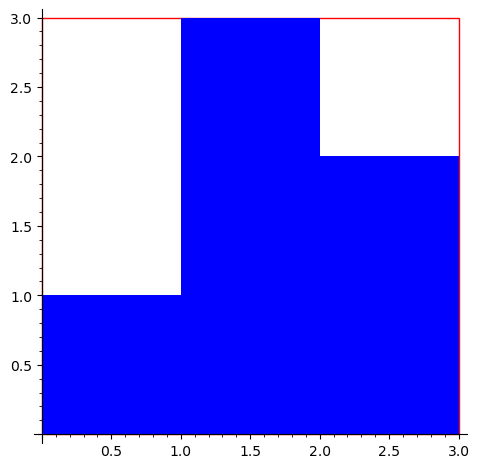

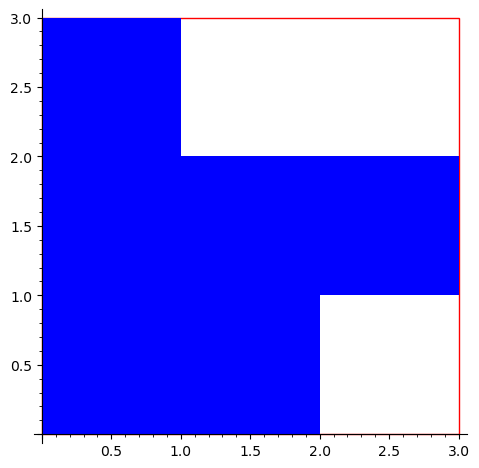

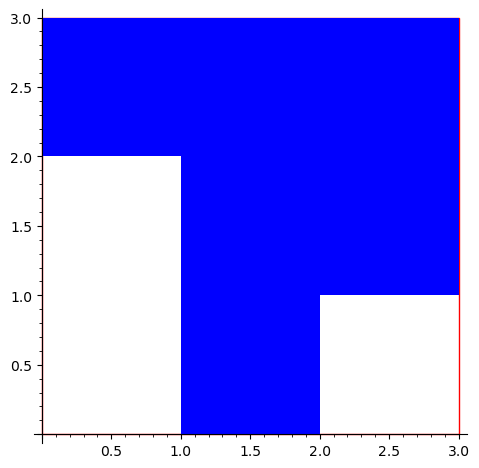

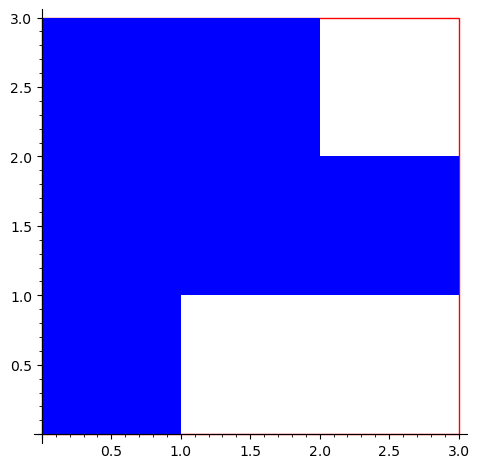

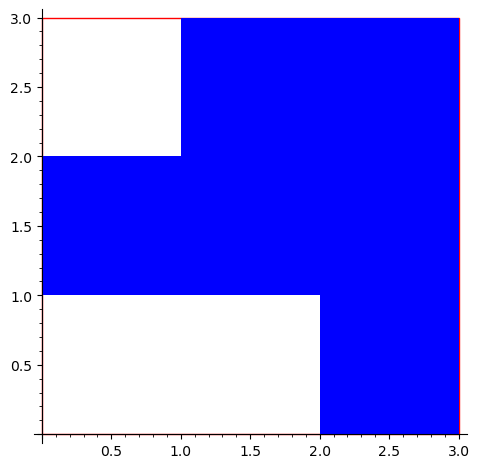

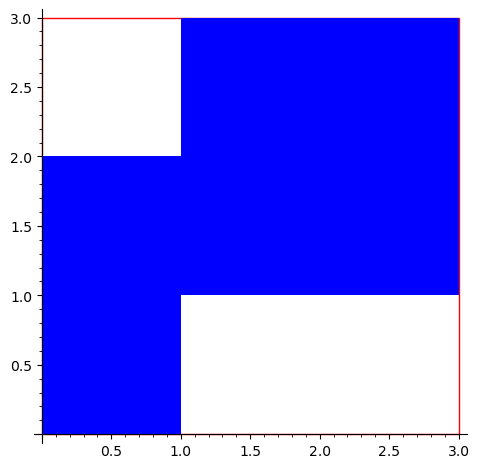

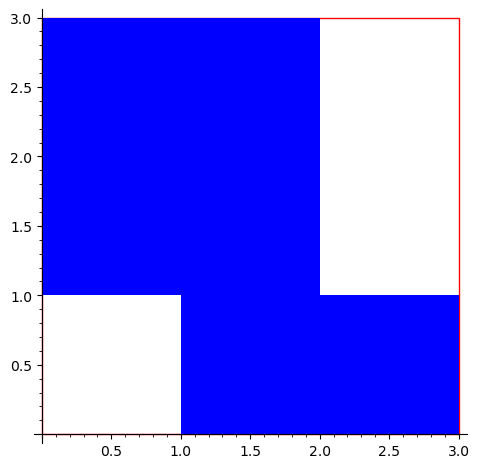

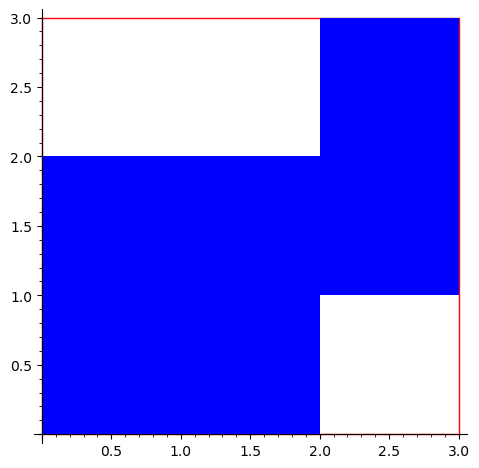

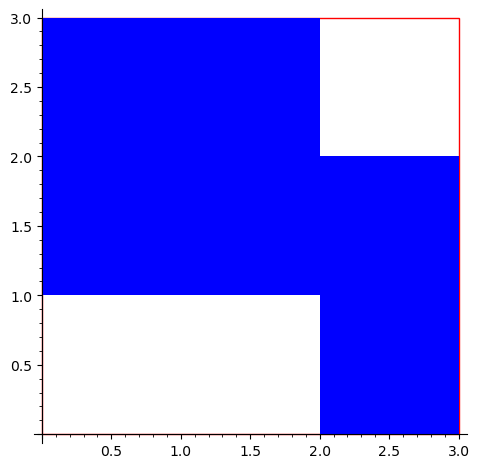

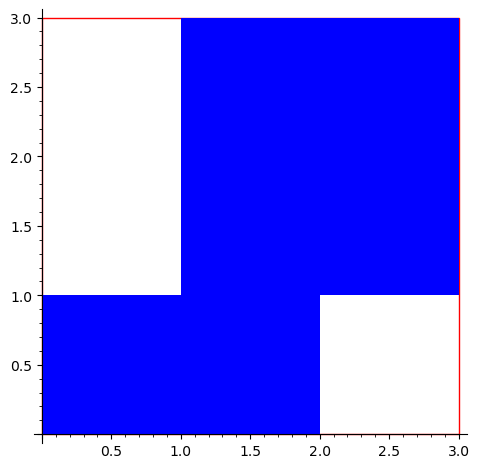

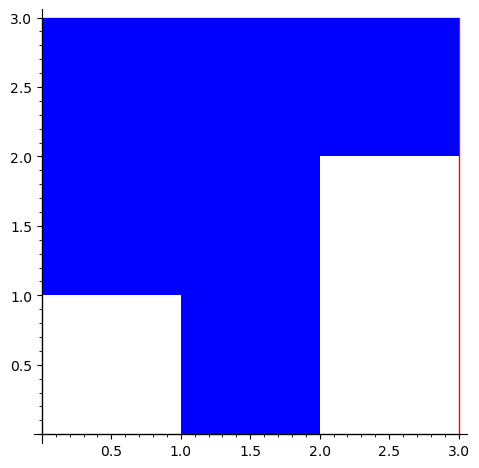

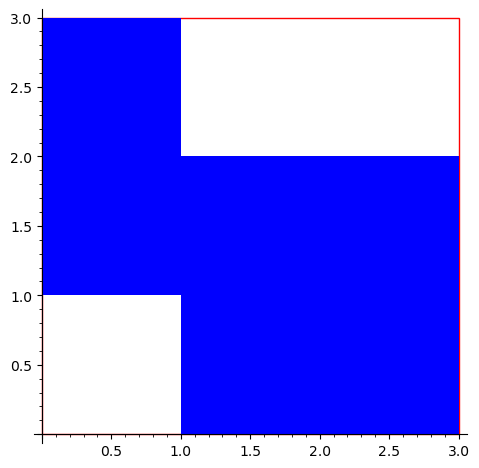

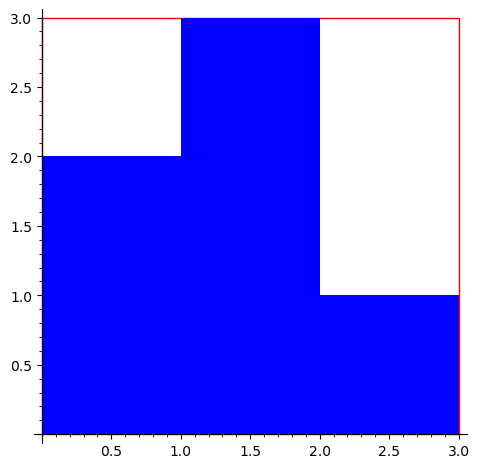

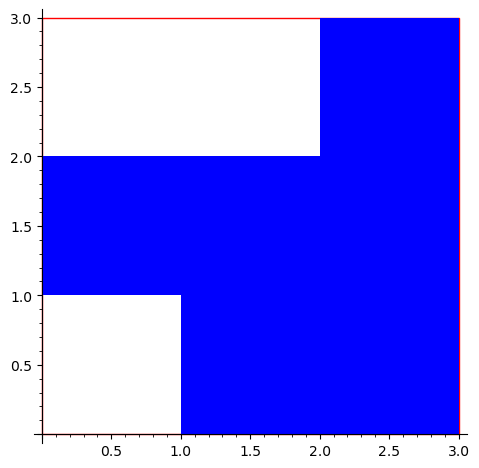

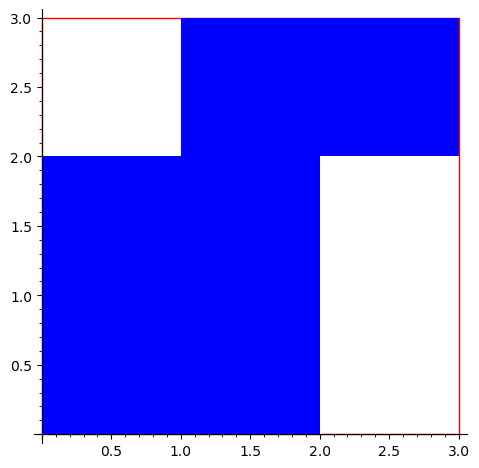

((6, 6, 4, 0, 0, 5.656854249492381),): 4
((6, 8, 3, 0, 0, 5.656854249492381),): 16


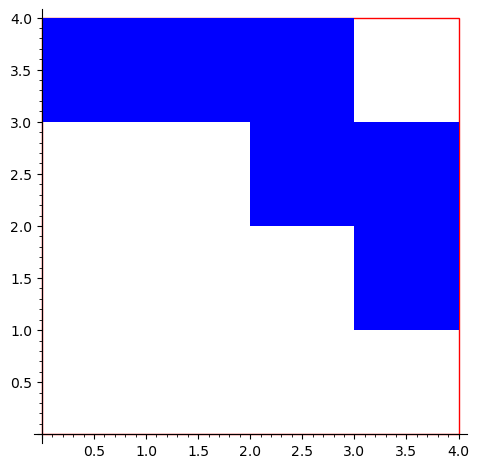

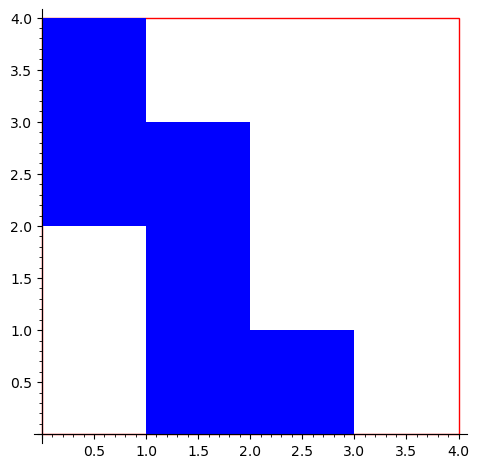

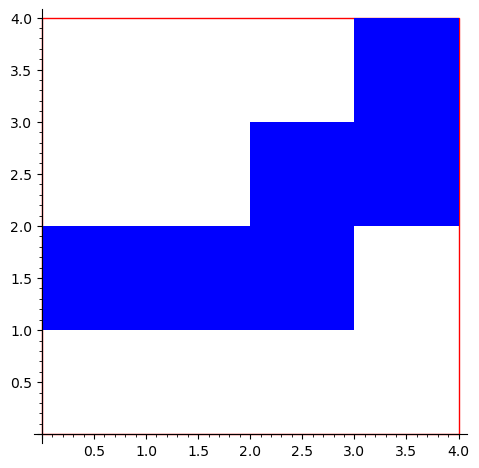

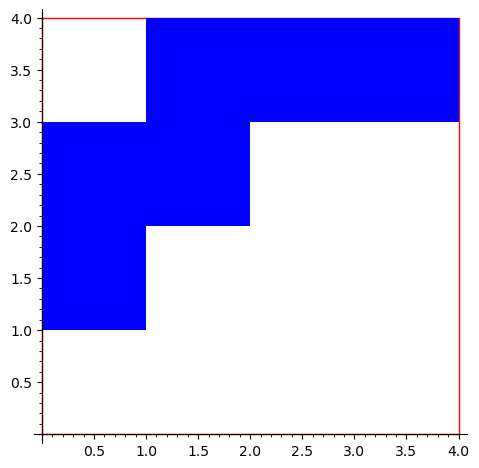

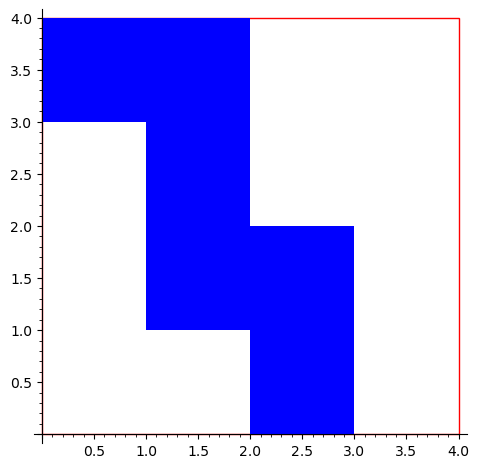

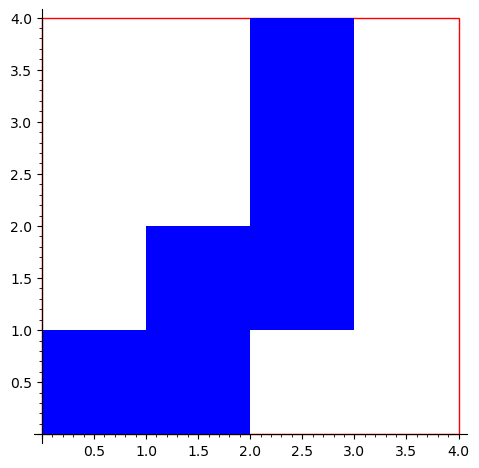

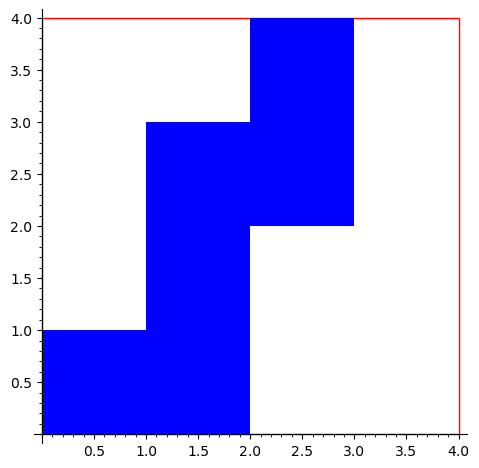

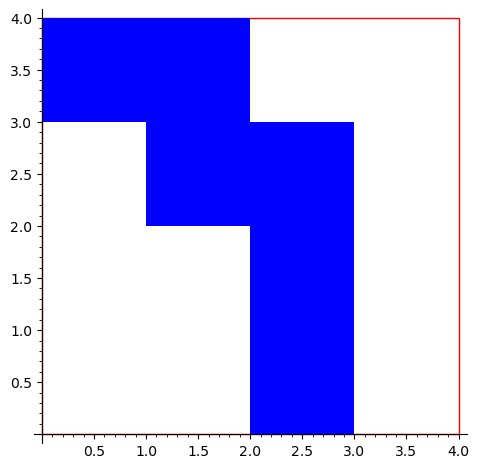

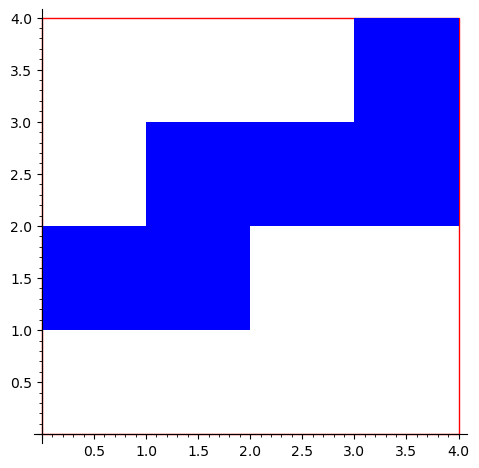

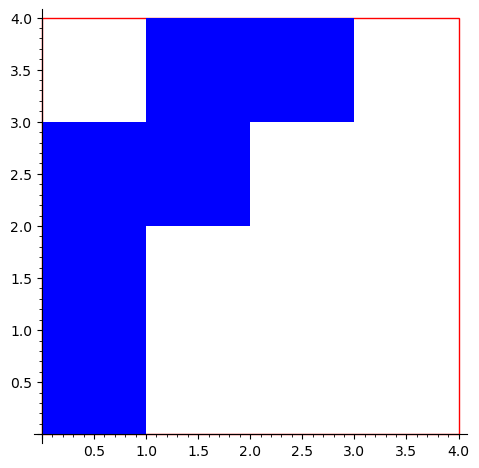

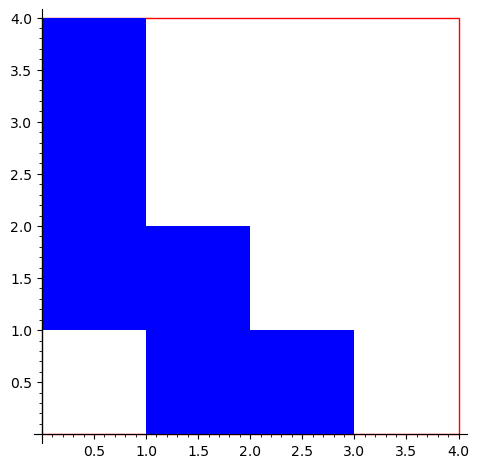

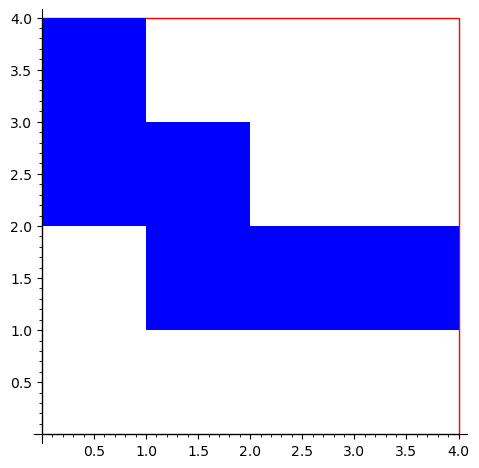

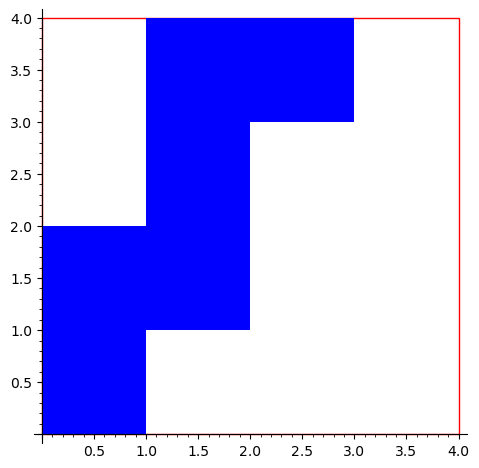

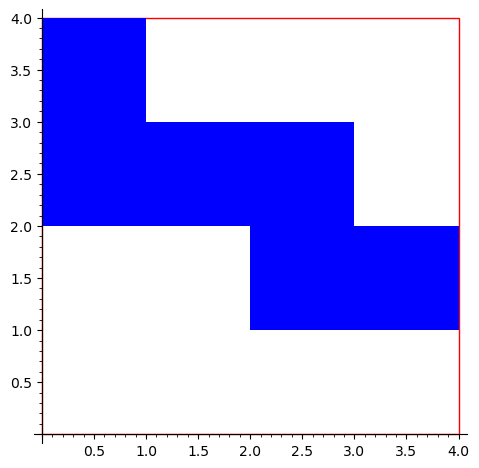

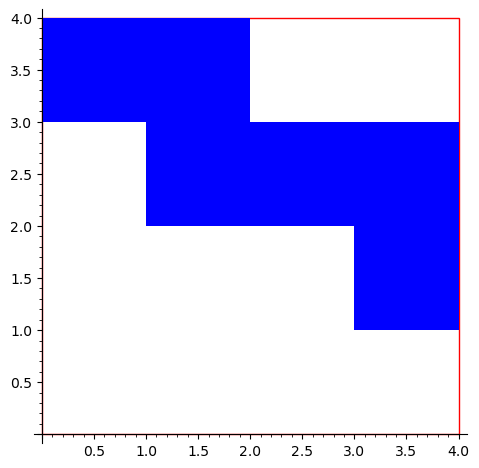

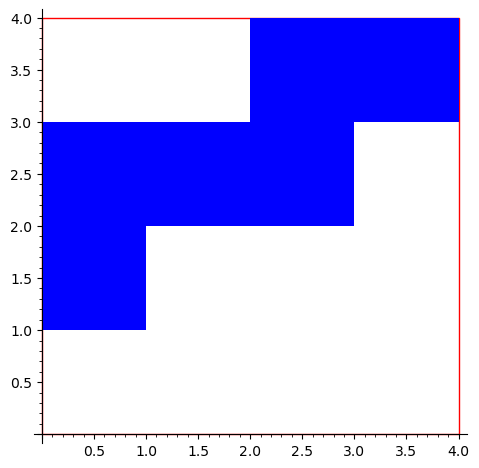

((6, 10, 1, 0, 0, 5.656854249492381),): 8
((6, 10, 2, 0, 0, 7.0710678118654755),): 12


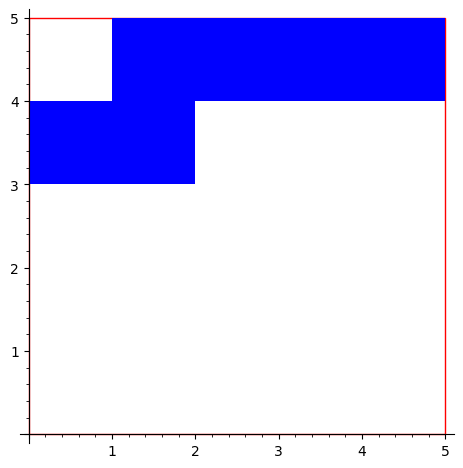

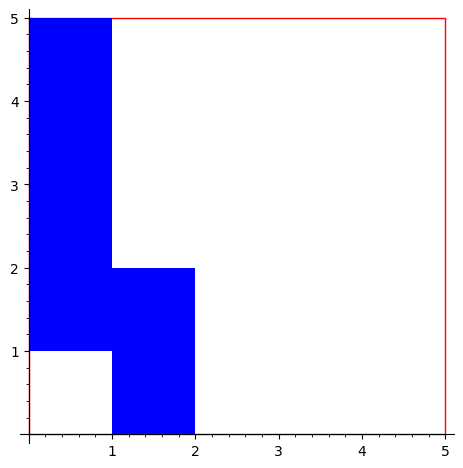

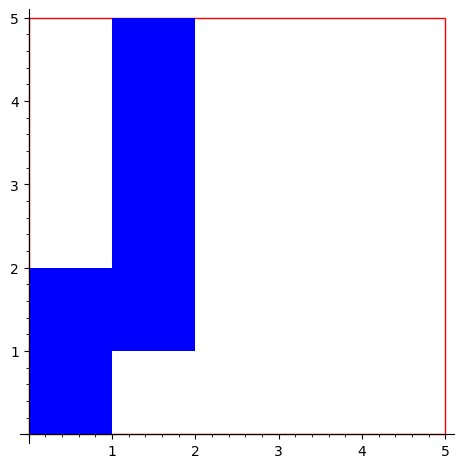

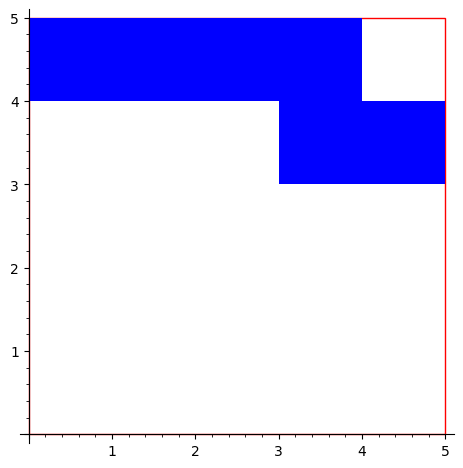

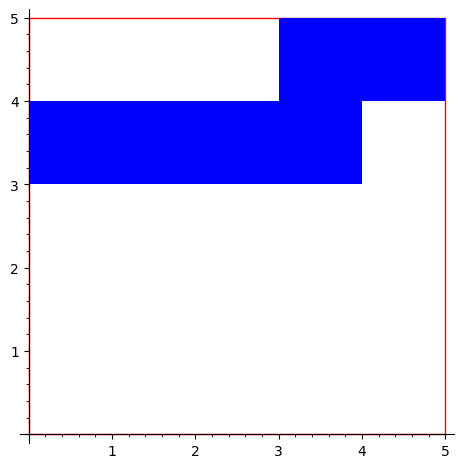

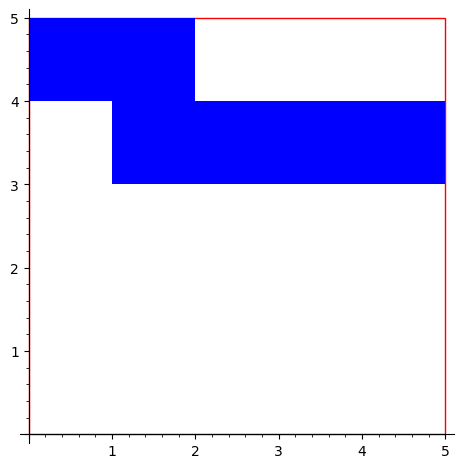

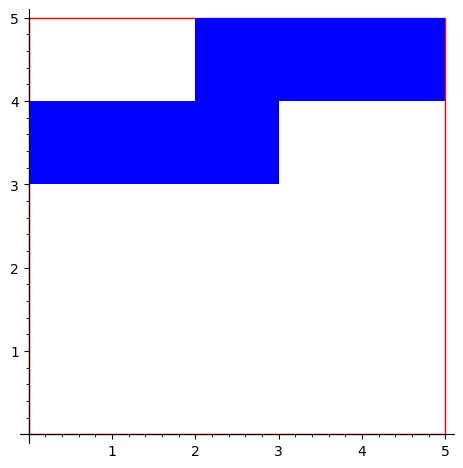

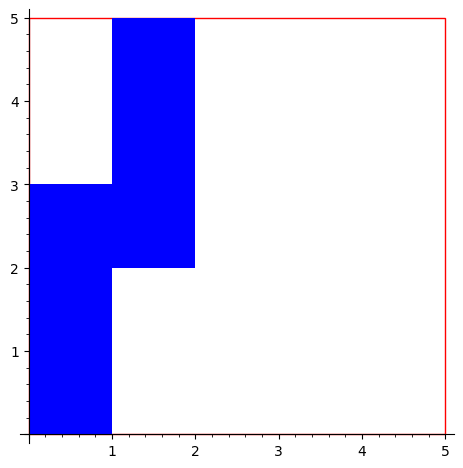

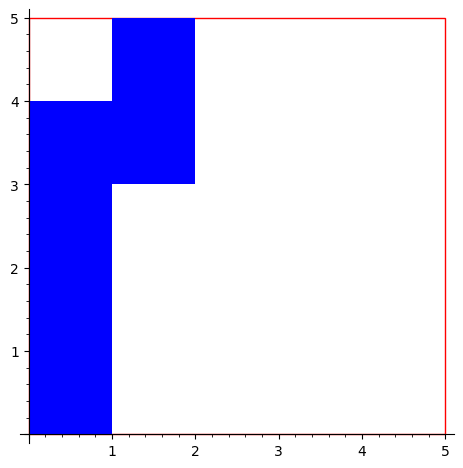

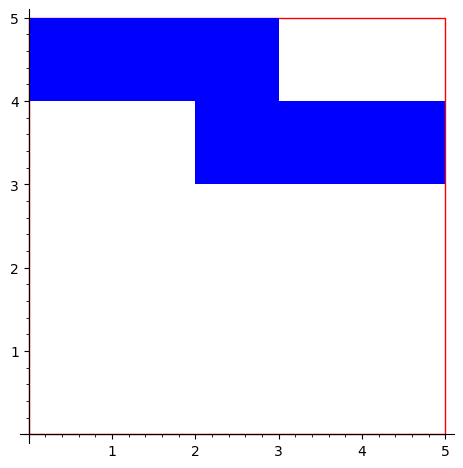

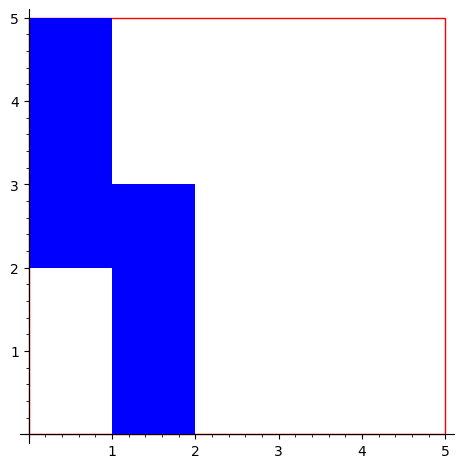

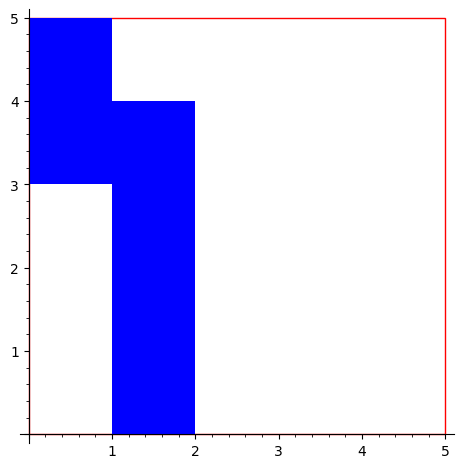

((6, 11, 0, 1, 0, 4.242640687119285),): 8
((6, 10, 0, 0, 0, 4.242640687119285),): 2
((6, 10, 2, 0, 0, 5.656854249492381),): 16


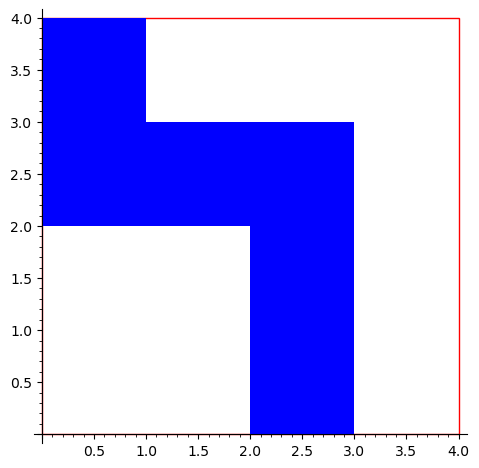

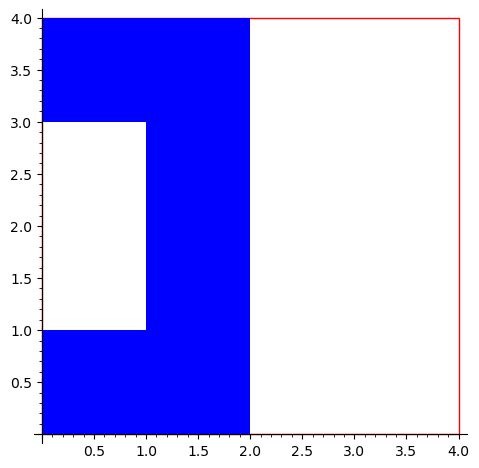

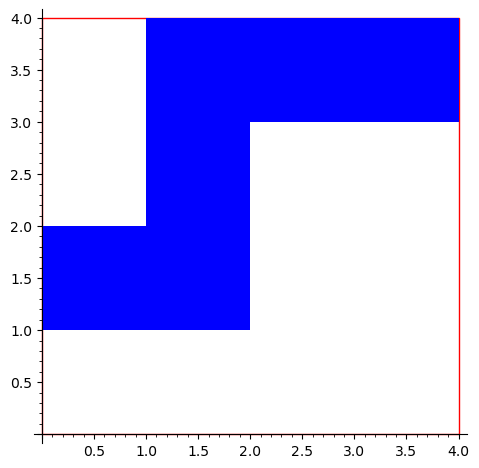

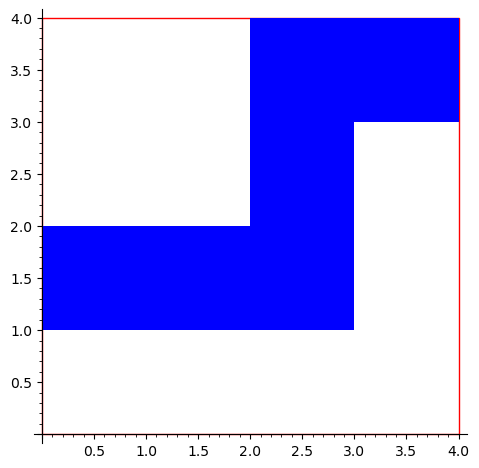

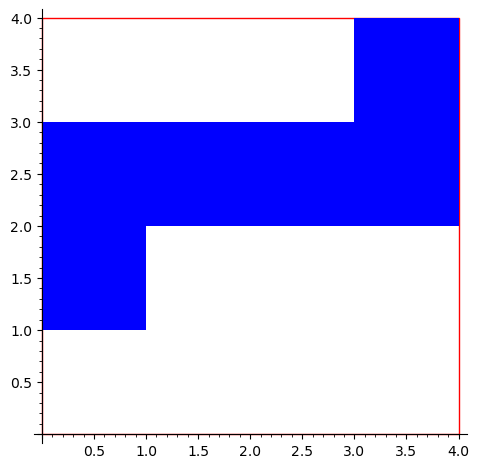

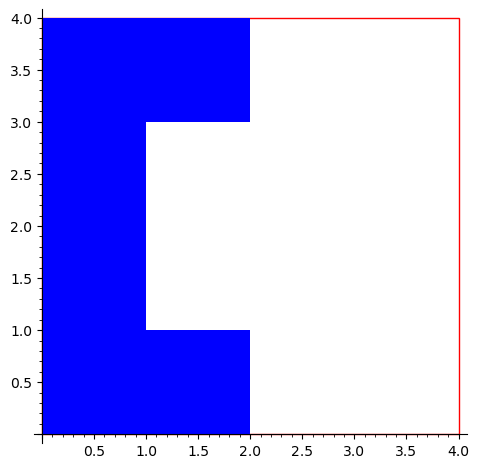

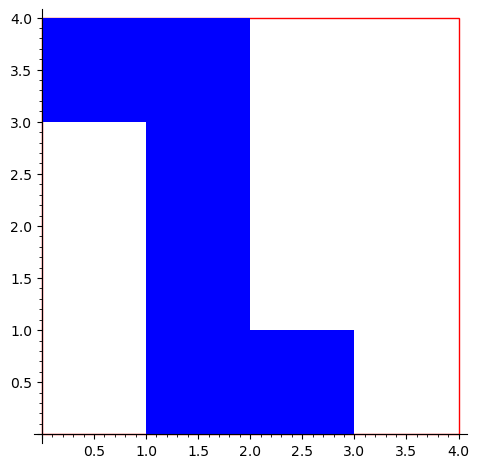

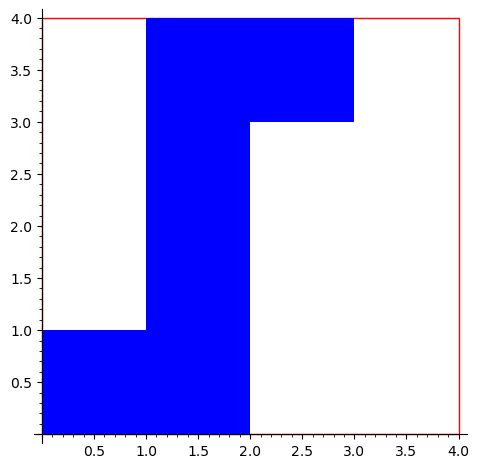

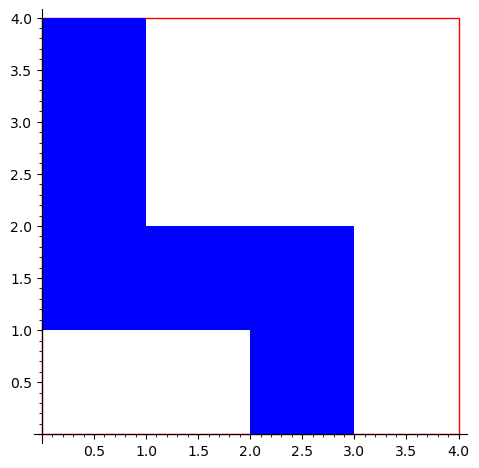

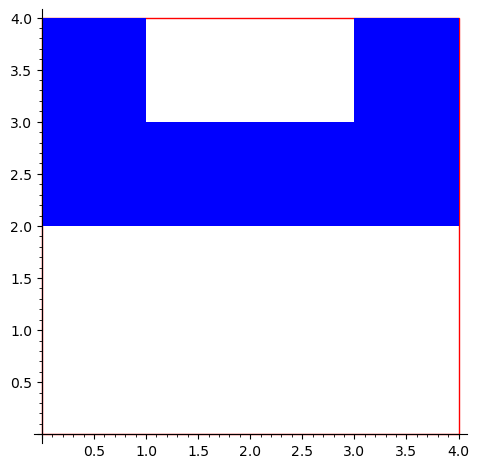

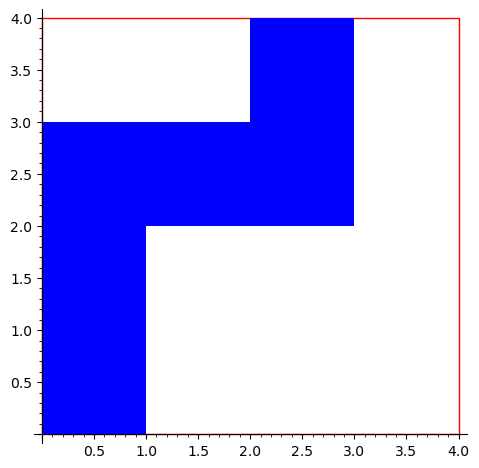

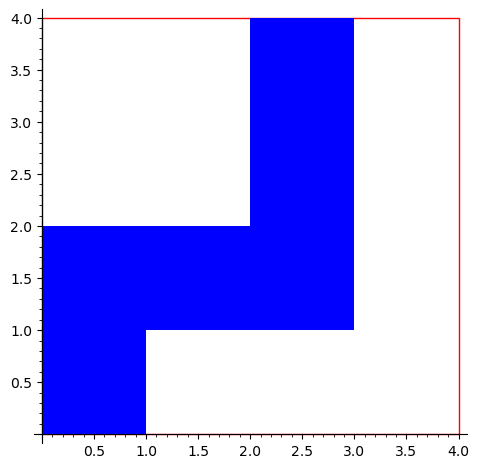

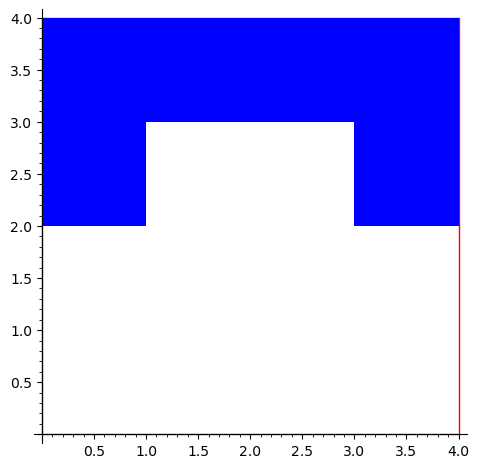

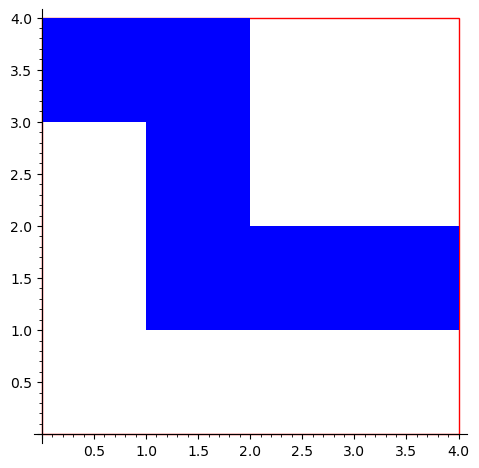

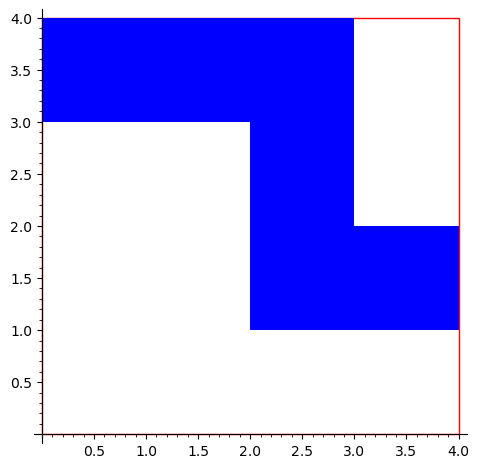

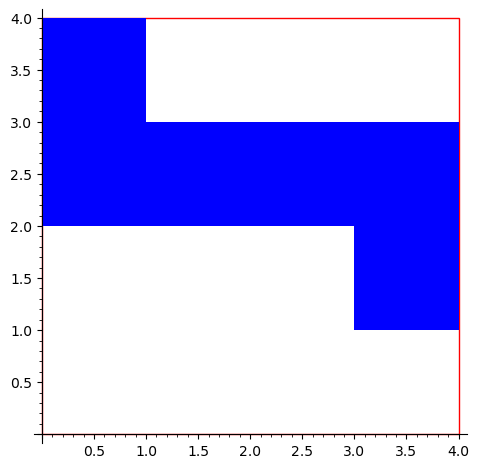

((6, 12, 1, 0, 0, 7.0710678118654755),): 8
((6, 12, 1, 0, 0, 5.656854249492381),): 8
((6, 8, 2, 0, 0, 5.656854249492381),): 4
((6, 9, 1, 1, 0, 5.656854249492381),): 8
((6, 14, 0, 0, 0, 8.48528137423857),): 2


In [122]:
g = generate_same_attributes(6, (attribute_test,))
for elt in g:
    print(f"{elt}: {len(g[elt])}")
    if len(g[elt]) > 8: 
        for p in g[elt]: draw(np.array(p)).show()

In [21]:
np.array([[1, 0, 1], [1, 1, 1]])

array([[1, 0, 1],
       [1, 1, 1]])

In [22]:
print(to_square(np.array([[1]])))
print(to_square(np.array([[0, 0], [1, 0]])))
print(to_square(np.array([[]])))
print(to_square(np.array([[0], [1], [0]])))
print(to_square(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]])))

[[1]]
[[0 0]
 [1 0]]
[[0]]
[[0 0 0]
 [1 0 0]
 [0 0 0]]
[[0 1 1]
 [1 0 1]
 [1 1 0]]


In [23]:
print(generate(np.array([[1]])))
print(generate(np.array([[0, 0], [1, 0]])))
print(generate(np.ones((0, 0))))
print(generate(np.array([[0], [1], [0]])))
print(generate(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]])))

[[1]]
[[1]]
[]
[[1]]
[[0 1 1]
 [1 0 1]
 [1 1 0]]


In [24]:
print(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]]))
print()
print(rotation(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]])))

[[0 1 1]
 [1 0 1]
 [1 1 0]]

[[1 1 0]
 [1 0 1]
 [0 1 1]]


In [25]:
print(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]]))
print()
print(classe_rotation(np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]])))

[[0 1 1]
 [1 0 1]
 [1 1 0]]

[array([[0, 1, 1],
       [1, 0, 1],
       [1, 1, 0]])]


In [26]:
x = np.array([[1,0,0],[1,0,0],[1,1,0]])
y = np.array([[0,0,0],[0,1,0],[0,0,0]])
print(x, end="\n\n")
print(symetrie_h(x), end="\n\n")
print(symetrie_v(x), end="\n\n")
print(classe_symetrie_mieux(x))
print(classe_symetrie_mieux(y))

[[1 0 0]
 [1 0 0]
 [1 1 0]]

[[1 1 0]
 [1 0 0]
 [1 0 0]]

[[0 0 1]
 [0 0 1]
 [0 1 1]]

[array([[1, 0, 0],
       [1, 0, 0],
       [1, 1, 0]]), array([[0, 0, 1],
       [0, 0, 1],
       [0, 1, 1]]), array([[0, 1, 1],
       [0, 0, 1],
       [0, 0, 1]]), array([[1, 1, 0],
       [1, 0, 0],
       [1, 0, 0]])]
[array([[0, 0, 0],
       [0, 1, 0],
       [0, 0, 0]])]


In [27]:
for i in range(1, 10):
    print(len(generate_all(i)))

1
2
6
15
42
112
308
825
2255


In [28]:
assert potential_degree(np.array([[0, 1, 0], [1, 1, 1]])) == 16
assert potential_degree(np.array([[1, 1, 0]])) == 8

assert perimeter(np.array([[1]])) == 4
assert perimeter(np.array([[1, 0, 0],
                           [1, 1, 1]])) == 10
assert perimeter(np.array([[0, 1, 0], [1, 1, 1]])) == 10
assert perimeter(np.array([[1, 0, 1], [1, 1, 1]])) == 12

assert real_degree(np.array([[0, 1, 0], [1, 1, 1]])) == 6

In [29]:
print(outline(np.array([[0, 1, 0], [1, 1, 1]])))
print(outline(np.array([[0, 0, 1], [1, 1, 1]])))  # Problem here (corrige dans outline2)
print(outline2(np.array([[0, 0, 1], [1, 1, 1]])))

[[0 0 1 0 0]
 [0 2 0 2 0]
 [1 0 0 0 1]
 [0 1 1 1 0]]
[[0 0 0 1 0]
 [0 1 1 1 1]
 [1 0 0 0 1]
 [0 1 1 1 0]]
[[0 0 0 1 0]
 [0 1 2 0 1]
 [1 0 0 0 1]
 [0 1 1 1 0]]


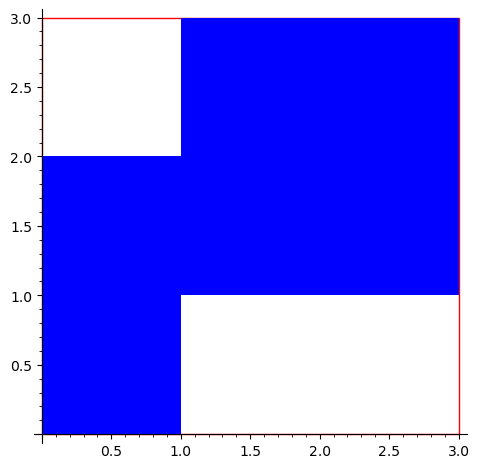

In [30]:
draw(np.array([[0, 1, 1], [1, 1, 1], [1, 0, 0]]))